В данном ноутбуке было исследовано несколько вариантов использования предобученной DenseNet121 с весами ImageNet:

1) Transfer learning без fine-tuning — база DenseNet121 полностью заморожена, обучается только классификационная часть с дополнительным SE-блоком.
2) Fine-tuning последних слоёв — после обучения классификационной части размораживались последние 80 слоёв DenseNet121 и выполнялось дообучение с меньшей скоростью обучения.
3) Полная разморозка — все слои DenseNet121 становились обучаемыми для адаптации модели к медицинским изображениям.

Был использован датасет с Kaggle: https://www.kaggle.com/datasets/ozguraslank/brain-stroke-ct-dataset

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

2025-12-01 17:36:27.031501: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764610587.231085      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764610587.291839      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input

In [ ]:
tf.random.set_seed(42)

data_path = "/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset"
num_class = {"Bleeding": 1, "Ischemia": 2, "Normal": 0}

img_size = (224, 224)
batch_size = 16

AUTOTUNE = tf.data.AUTOTUNE
SEED = 42

In [ ]:
def collect_image_pairs(data_path, num_class):
    triples = []
    for cls_name, cls_id in num_class.items():
        img_dir = os.path.join(data_path, cls_name, "PNG")

        if not os.path.exists(img_dir):
            print(f"Нет PNG для класса {cls_name}: {img_dir}")
            continue

        img_paths = sorted(glob.glob(os.path.join(img_dir, "*.png")))
        for img_p in img_paths:
            triples.append((img_p, cls_id))

    return triples

triples = collect_image_pairs(data_path, num_class)
print("Всего изображений:", len(triples))

Всего изображений: 6650


In [ ]:
def balance_by_undersample(triples, seed=SEED):
    by_class = {}
    for p, cid in triples:
        by_class.setdefault(cid, []).append(p)

    sizes = {cid: len(lst) for cid, lst in by_class.items()}
    print("До балансировки:", sizes)

    min_size = min(sizes.values())
    rng = random.Random(seed)
    balanced = []

    for cid, paths in by_class.items():
        sampled = rng.sample(paths, min_size) if len(paths) > min_size else paths
        balanced += [(p, cid) for p in sampled]

    rng.shuffle(balanced)
    print("После балансировки:",
          {cid: sum(1 for _, c in balanced if c == cid) for cid in by_class})

    return balanced

balanced_pairs = balance_by_undersample(triples)

До балансировки: {1: 1093, 2: 1130, 0: 4427}
После балансировки: {1: 1093, 2: 1093, 0: 1093}


In [ ]:
image_paths = [p for p, c in balanced_pairs]
labels = np.array([c for p, c in balanced_pairs])

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels, test_size=0.30, random_state=SEED, stratify=labels)

print("Train:", len(train_paths), " Val:", len(val_paths))

Train: 2295  Val: 984


ФОРМИРОВАНИЕ ТЕСТОВОГО НАБОРА ДАННЫХ

In [ ]:
import pandas as pd

test_root = "/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test"
test_labels_csv = os.path.join(test_root, "labels_new.csv")

df_raw = pd.read_csv(test_labels_csv)

df_test = df_raw["labels"].str.split(";", expand=True)
df_test.columns = ["image_id", "Stroke"]

df_test = df_test[df_test["image_id"] != "image_id"]

df_test["image_id"] = df_test["image_id"].astype(str)
df_test["Stroke"] = df_test["Stroke"].astype(int)

test_label_dict = dict(zip(df_test["image_id"], df_test["Stroke"]))

print(df_test)


    image_id  Stroke
1      10189       0
2      10200       0
3      10231       0
4      10267       0
5      10300       0
..       ...     ...
196    16026       2
197    16478       2
198    16607       2
199    16643       2
200    17017       2

[200 rows x 2 columns]


In [ ]:
test_png_dir = os.path.join(test_root, "PNG")

test_paths = []
test_labels = []

for i, row in df_test.iterrows():
    fname = str(row["image_id"]) + ".png"
    label = int(row["Stroke"])

    img_path = os.path.join(test_png_dir, fname)

    if os.path.exists(img_path):
        test_paths.append(img_path)
        test_labels.append(label)
    else:
        print("Файл не найден:", img_path)

test_labels = np.array(test_labels, dtype=np.int32)

print("Test samples:", len(test_paths))
print("Классов в тесте:", {i: list(test_labels).count(i) for i in sorted(set(test_labels))})


Test samples: 200
Классов в тесте: {0: 137, 1: 35, 2: 28}


In [ ]:
import tensorflow as tf

num_channels = 1

def load_image(path, channels=num_channels):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=channels)  # (H, W, 1)
    img = tf.image.convert_image_dtype(img, tf.float32)  # [0,1]
    img = tf.image.resize(img, img_size)

    img = tf.image.grayscale_to_rgb(img) # (H, W, 3)

    return img


In [ ]:
def make_test_dataset(img_paths, labels):
    ds_img = tf.data.Dataset.from_tensor_slices(img_paths)
    ds_lbl = tf.data.Dataset.from_tensor_slices(labels)

    def _load(img_p, label):
        img = load_image(img_p)
        return img, label

    ds = tf.data.Dataset.zip((ds_img, ds_lbl))
    ds = ds.map(_load, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

test_ds = make_test_dataset(test_paths, test_labels)


I0000 00:00:1764610653.578212      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1764610653.578868      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [ ]:
for imgs, labels in test_ds.take(1):
    print("Batch images:", imgs.shape)
    print("Batch labels:", labels.numpy())

Batch images: (16, 224, 224, 3)
Batch labels: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
print(test_paths[:10])
print(test_labels[:10])


['/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10189.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10200.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10231.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10267.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10300.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10301.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10319.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10360.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10467.png', '/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset/External_Test/PNG/10493.png']
[0 0 0 0 0 0 0 0 0 0]


ФОРМИРОВАНИЕ ОБУЧ/ВАЛИД ДАТАСЕТОВ (ПРОБНЫЙ ВАРИАНТ)

In [ ]:
def random_gamma(img, min_gain=0.85, max_gain=1.15):
    g = tf.random.uniform([], min_gain, max_gain)
    img = tf.image.adjust_gamma(img, gamma=g)
    return img

def random_noise(img, std=0.01):
    noise = tf.random.normal(shape=tf.shape(img), mean=0.0, stddev=std)
    img = img + noise
    return tf.clip_by_value(img, 0.0, 1.0)

In [ ]:
import cv2
def elastic_transform_np(image, alpha=5, sigma=4):
    shape = image.shape[:2]
    dx = (cv2.GaussianBlur((np.random.rand(*shape) * 2 - 1).astype(np.float32), (17,17), sigma) * alpha).astype(np.float32)
    dy = (cv2.GaussianBlur((np.random.rand(*shape) * 2 - 1).astype(np.float32), (17,17), sigma) * alpha).astype(np.float32)
    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    map_x = (x + dx).astype(np.float32)
    map_y = (y + dy).astype(np.float32)
    res = cv2.remap((image*255).astype(np.uint8), map_x, map_y, interpolation=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
    res = res.astype(np.float32) / 255.0
    return res

In [ ]:
def elastic_tf(img):
    def _np(img_np):
        return elastic_transform_np(img_np, alpha=3.0, sigma=4.0)
    img2 = tf.numpy_function(_np, [img], tf.float32)
    img2.set_shape(img.shape)
    return img2

In [ ]:
def preprocess_path(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=1) # grayscale
    img = tf.image.convert_image_dtype(img, tf.float32) # [0,1]
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img) # 3 канала
    img = densenet_preprocess(img)
    return img, label

In [ ]:
def augment(img, label):
    return img, label

In [ ]:
def safe_decode_png(path):
    img_bytes = tf.io.read_file(path)
    img = tf.image.decode_png(img_bytes, channels=1, dtype=tf.uint8)

    if tf.size(img) == 0:
        img = tf.zeros([512, 512, 1], dtype=tf.uint8)

    if tf.rank(img) == 2:
        img = tf.expand_dims(img, axis=-1)

    img.set_shape([None, None, 1])

    return img

In [ ]:
def parse_and_preprocess_train(path, label):
    img = safe_decode_png(path)

    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)

    if tf.random.uniform(()) < 0.1:
        img = tf.image.random_brightness(img, max_delta=0.1)

    if tf.random.uniform(()) < 0.1:
        img = tf.image.random_contrast(img, 0.9, 1.1)

    img = tf.image.resize(img, img_size)

    img = tf.image.grayscale_to_rgb(img)

    img = densenet_preprocess(img)

    return img, label

In [ ]:
def parse_and_preprocess_eval(path, label):
    img = safe_decode_png(path)
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = densenet_preprocess(img)
    return img, label

In [ ]:
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess


def build_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
        ds = ds.map(parse_and_preprocess_train, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(parse_and_preprocess_eval, num_parallel_calls=AUTOTUNE)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

In [ ]:
train_ds = build_dataset(train_paths, train_labels, training=True)
val_ds = build_dataset(val_paths, val_labels, training=False)

In [ ]:
for imgs, labs in train_ds.take(1):
    print("Train batch shape:", imgs.shape, "dtype:", imgs.dtype, "labs:", labs.numpy()[:8])
for imgs, labs in val_ds.take(1):
    print("Val batch shape:", imgs.shape)
for imgs, labs in test_ds.take(1):
    print("Test batch shape:", imgs.shape)

Train batch shape: (16, 224, 224, 3) dtype: <dtype: 'float32'> labs: [2 0 1 0 2 2 2 1]
Val batch shape: (16, 224, 224, 3)
Test batch shape: (16, 224, 224, 3)


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

num_cl = 3

cls_ids = np.unique(train_labels)
class_weights_arr = compute_class_weight(class_weight='balanced', classes=cls_ids, y=train_labels)
cw = np.ones(num_cl, dtype=np.float32)
for i, c in enumerate(cls_ids):
    cw[c] = class_weights_arr[i]
print("class_weights vector:", cw)

class_weights vector: [1. 1. 1.]


In [ ]:
def sparse_focal_loss(gamma=2.0, alpha=None):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
        true_probs = tf.reduce_sum(tf.one_hot(y_true, depth=tf.shape(y_pred)[-1]) * y_pred, axis=-1)
        modulating = tf.pow(1.0 - true_probs, gamma)
        if alpha is None:
            alpha_factor = 1.0
        else:
            if np.ndim(alpha) == 0:
                alpha_factor = alpha
            else:
                alpha_tensor = tf.constant(alpha, dtype=tf.float32)
                alpha_factor = tf.gather(alpha_tensor, y_true)
        loss = - alpha_factor * modulating * tf.math.log(true_probs)
        return tf.reduce_mean(loss)
    return loss_fn

In [ ]:
alpha = cw.copy().astype(np.float32)
alpha = alpha / np.mean(alpha)
loss_fn = sparse_focal_loss(gamma=2.0, alpha=alpha)

Вариант 1 — построение DenseNet + SE-голова; по умолчанию все слои base делаются либо trainable=False (заморожены), либо True в зависимости от аргумента base_trainable. После этого обучается голова (и, если base_trainable=True, то и базовая сеть).

Если base_trainable=False, то в trainable params попадет только голова (несколько десятков тысяч весов). Обучение быстрое, низкий риск переобучения, но ограниченная способность адаптироваться к медицинской доменной специфике (CT отличается от ImageNet).

Если base_trainable=True, то все обучается с нуля от предобученных весов (большинство параметров trainable). Обычно в таком случае ставится маленький LR и/или сначала обучается голова, затем тонкая настройка (partial fine-tune).

In [ ]:
def se_block(x, reduction=16):
    ch = x.shape[-1]
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(max(ch//reduction, 4), activation='relu')(se)
    se = layers.Dense(ch, activation='sigmoid')(se)
    se = layers.Reshape((1,1,ch))(se)
    return layers.Multiply()([x, se])

In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import DenseNet121

def build_model_densenet_se(input_shape=(img_size[0], img_size[1], 3), n_classes=num_cl, base_trainable=False):
    base = DenseNet121(include_top=False, weights="imagenet", input_shape=input_shape)
    for layer in base.layers:
        layer.trainable = base_trainable
    x = base.output
    x = se_block(x, reduction=16)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    model = models.Model(inputs=base.input, outputs=out)
    return model

model = build_model_densenet_se(base_trainable=False)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_2    │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d_2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_3    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_3… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,433,859 (28.36 MB)

 Trainable params: 395,843 (1.51 MB)

 Non-trainable params: 7,038,016 (26.85 MB)

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss=loss_fn,
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='sparse_categorical_accuracy')])

In [ ]:
ckpt = callbacks.ModelCheckpoint("best_densenet_se.h5", monitor="val_sparse_categorical_accuracy", mode="max", save_best_only=True, verbose=1)
es = callbacks.EarlyStopping(monitor="val_sparse_categorical_accuracy", patience=6, restore_best_weights=True, verbose=1)
rlr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)

In [ ]:
history = model.fit(train_ds,
                    validation_data=val_ds,
                    epochs=100,
                    callbacks=[ckpt, es, rlr])

Epoch 1/100


I0000 00:00:1764610951.452398     112 service.cc:148] XLA service 0x7fc9b0006020 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1764610951.453283     112 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1764610951.453303     112 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1764610954.343662     112 cuda_dnn.cc:529] Loaded cuDNN version 90300


  2/144 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - loss: 1.2480 - sparse_categorical_accuracy: 0.2812    

I0000 00:00:1764610965.937663     112 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - loss: 1.0796 - sparse_categorical_accuracy: 0.3799
Epoch 1: val_sparse_categorical_accuracy improved from -inf to 0.52744, saving model to best_densenet_se.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 74s 322ms/step - loss: 1.0792 - sparse_categorical_accuracy: 0.3801 - val_loss: 0.4283 - val_sparse_categorical_accuracy: 0.5274 - learning_rate: 1.0000e-04
Epoch 2/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.8892 - sparse_categorical_accuracy: 0.4362
Epoch 2: val_sparse_categorical_accuracy improved from 0.52744 to 0.58333, saving model to best_densenet_se.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - loss: 0.8885 - sparse_categorical_accuracy: 0.4365 - val_loss: 0.3892 - val_sparse_categorical_accuracy: 0.5833 - learning_rate: 1.0000e-04
Epoch 3/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.7859 - sparse_categorical_accuracy: 0.4744
Epoch 3: val_sparse_categorical_accuracy did not improve from 0.58333
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - loss: 0.7857 - sparse_categorical_accuracy: 0.4744 - val_loss: 0.4108 - val_sparse_categorical_accuracy: 0.5793 - learning_rate: 1.0000e-04
Epoch 4/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.6967 - sparse_categorical_accuracy: 0.5049
Epoch 4: val_sparse_categorical_accuracy did not improve from 0.58333
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - loss: 0.6964 - sparse_categorical_accuracy: 0.5050 - val_loss: 0.3725 - val_sparse_categorical_accuracy: 0.5783 - learning_rate: 1.0000e-04
Epoch 5/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.6627 - sparse_categorical_a

144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - loss: 0.6623 - sparse_categorical_accuracy: 0.4996 - val_loss: 0.3260 - val_sparse_categorical_accuracy: 0.6504 - learning_rate: 1.0000e-04
Epoch 6/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.5771 - sparse_categorical_accuracy: 0.5401
Epoch 6: val_sparse_categorical_accuracy improved from 0.65041 to 0.67073, saving model to best_densenet_se.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - loss: 0.5772 - sparse_categorical_accuracy: 0.5399 - val_loss: 0.3057 - val_sparse_categorical_accuracy: 0.6707 - learning_rate: 1.0000e-04
Epoch 7/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.5482 - sparse_categorical_accuracy: 0.5483
Epoch 7: val_sparse_categorical_accuracy did not improve from 0.67073
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - loss: 0.5481 - sparse_categorical_accuracy: 0.5483 - val_loss: 0.3060 - val_sparse_categorical_accuracy: 0.6677 - learning_rate: 1.0000e-04
Epoch 8/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.5325 - sparse_categorical_accuracy: 0.5610
Epoch 8: val_sparse_categorical_accuracy did not improve from 0.67073
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - loss: 0.5326 - sparse_categorical_accuracy: 0.5609 - val_loss: 0.3158 - val_sparse_categorical_accuracy: 0.6667 - learning_rate: 1.0000e-04
Epoch 9/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.5542 - sparse_categorical_a

144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - loss: 0.5395 - sparse_categorical_accuracy: 0.5286 - val_loss: 0.2874 - val_sparse_categorical_accuracy: 0.6900 - learning_rate: 5.0000e-05
Epoch 11/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.4878 - sparse_categorical_accuracy: 0.5748
Epoch 11: val_sparse_categorical_accuracy improved from 0.69004 to 0.70630, saving model to best_densenet_se.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - loss: 0.4877 - sparse_categorical_accuracy: 0.5749 - val_loss: 0.2823 - val_sparse_categorical_accuracy: 0.7063 - learning_rate: 5.0000e-05
Epoch 12/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.5043 - sparse_categorical_accuracy: 0.5575
Epoch 12: val_sparse_categorical_accuracy did not improve from 0.70630
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 68ms/step - loss: 0.5043 - sparse_categorical_accuracy: 0.5576 - val_loss: 0.2833 - val_sparse_categorical_accuracy: 0.7012 - learning_rate: 5.0000e-05
Epoch 13/100
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.5008 - sparse_categorical_accuracy: 0.5576
Epoch 13: val_sparse_categorical_accuracy did not improve from 0.70630
144/144 ━━━━━━━━━━━━━━━━━━━━ 10s 67ms/step - loss: 0.5009 - sparse_categorical_accuracy: 0.5576 - val_loss: 0.2856 - val_sparse_categorical_accuracy: 0.6900 - learning_rate: 5.0000e-05
Epoch 14/100
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.5044 - sparse_categori

In [ ]:
def fine_tune(model, n_unfreeze=100, lr=1e-5):
    base = None
    for l in model.layers:
        if isinstance(l, tf.keras.Model) and 'densenet' in l.name:
            base = l
            break
    if base is None:
        for layer in model.layers:
            if 'conv1_conv' in layer.name:
                base = model
                break
    if base is not None:
        for layer in base.layers[-n_unfreeze:]:
            layer.trainable = True
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss=loss_fn,
                  metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='sparse_categorical_accuracy')])
    return model

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)


13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 581ms/step - loss: 0.4091 - sparse_categorical_accuracy: 0.6021
Test loss: 0.41408535838127136
Test accuracy: 0.5699999928474426


1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step
Accuracy: 0.57
Classification report:
               precision    recall  f1-score   support

           0     0.8438    0.5912    0.6953       137
           1     0.3171    0.7429    0.4444        35
           2     0.3182    0.2500    0.2800        28

    accuracy                         0.5700       200
   macro avg     0.4930    0.5280    0.4732       200
weighted avg     0.6780    0.5700    0.5932       200



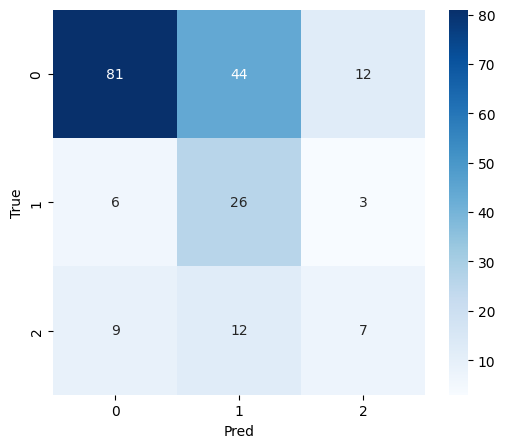

ROC AUC per class: [0.7814853435291391, 0.8161038961038961, 0.7367109634551495]


In [ ]:
def evaluate_and_report(model, ds, paths=None, labels_array=None):
    y_true = []
    y_pred = []
    probs = []
    for imgs, labs in ds:
        preds = model.predict(imgs)
        probs.append(preds)
        y_pred.extend(np.argmax(preds, axis=1).tolist())
        y_true.extend(labs.numpy().tolist())
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    print("Accuracy:", np.mean(y_true == y_pred))
    print("Classification report:\n", classification_report(y_true, y_pred, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues'); plt.xlabel("Pred"); plt.ylabel("True"); plt.show()
    try:
        probs = np.vstack(probs)
        y_bin = (np.arange(num_cl) == y_true.reshape(-1,1)).astype(int)
        aucs = []
        for i in range(num_cl):
            auc = roc_auc_score(y_bin[:, i], probs[:, i])
            aucs.append(auc)
        print("ROC AUC per class:", aucs)
    except Exception as e:
        print("ROC error:", e)
    return y_true, y_pred

y_true_test, y_pred_test = evaluate_and_report(model, test_ds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


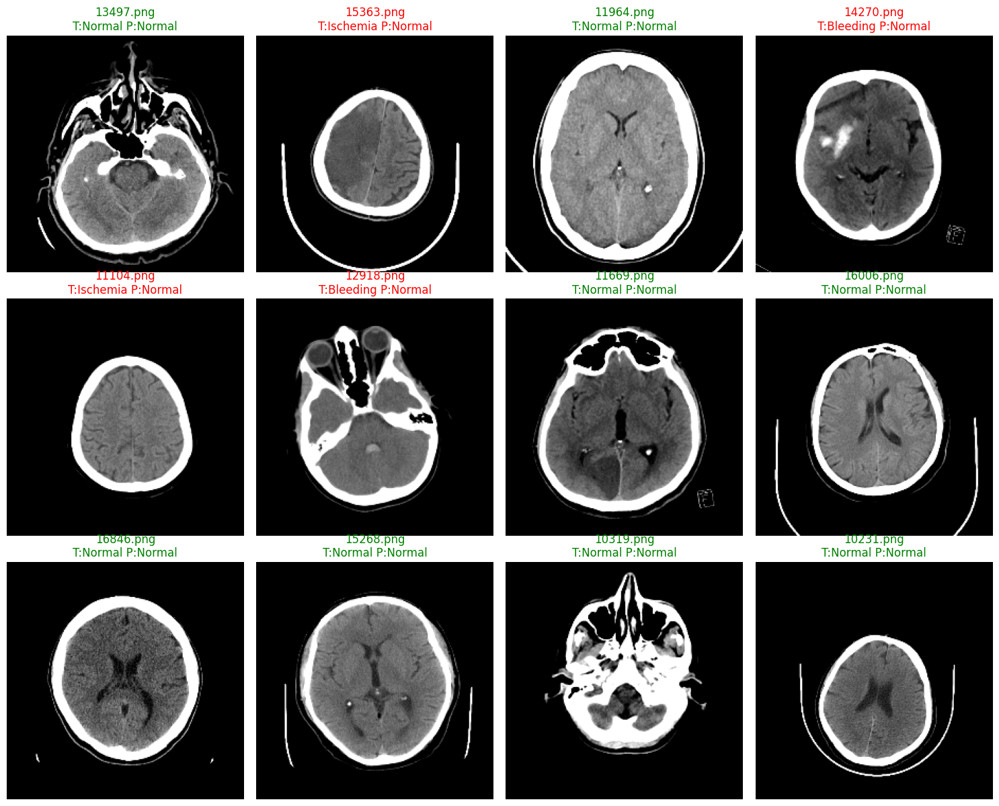

In [ ]:
class_names = ["Normal", "Bleeding", "Ischemia"]
def show_test_predictions(model, paths, labels, n=12):
    plt.figure(figsize=(15, 12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    for i, idx in enumerate(idxs):
        img_raw = tf.io.read_file(paths[idx])
        img = tf.image.decode_png(img_raw, channels=1)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img_r = tf.image.resize(img, img_size)
        img3 = tf.image.grayscale_to_rgb(img_r)
        inp = densenet_preprocess(img3)
        pred = model.predict(tf.expand_dims(inp, axis=0))
        pcls = np.argmax(pred, axis=1)[0]
        tcls = labels[idx]
        plt.subplot(int(np.ceil(n/4)), 4, i+1)
        plt.imshow(img_r[:, :, 0], cmap='gray')
        color = "green" if int(pcls)==int(tcls) else "red"
        fname = os.path.basename(paths[idx])
        plt.title(f"{fname}\nT:{class_names[int(tcls)]} P:{class_names[int(pcls)]}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

show_test_predictions(model, test_paths, test_labels, n=12)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


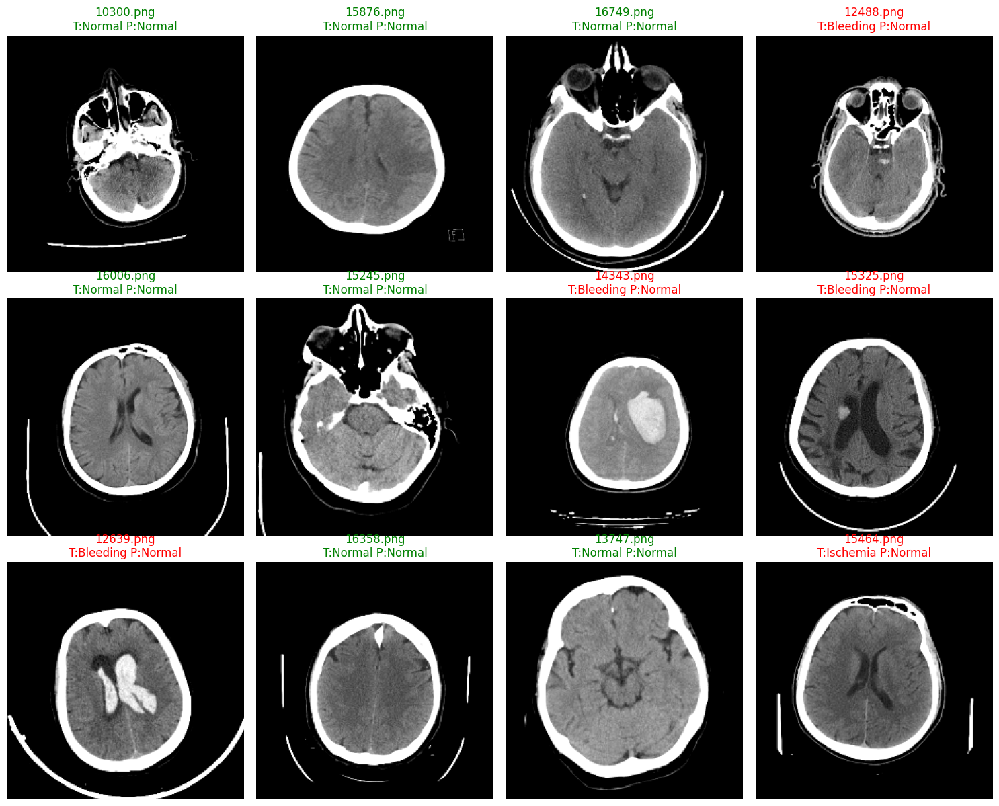

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


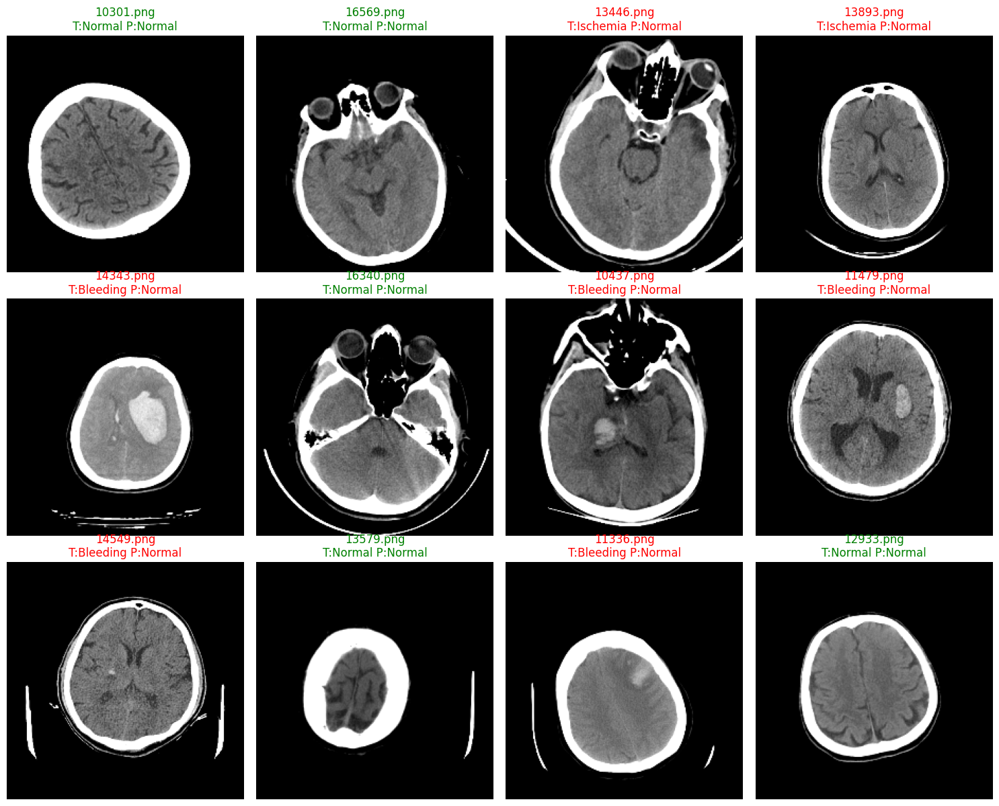

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


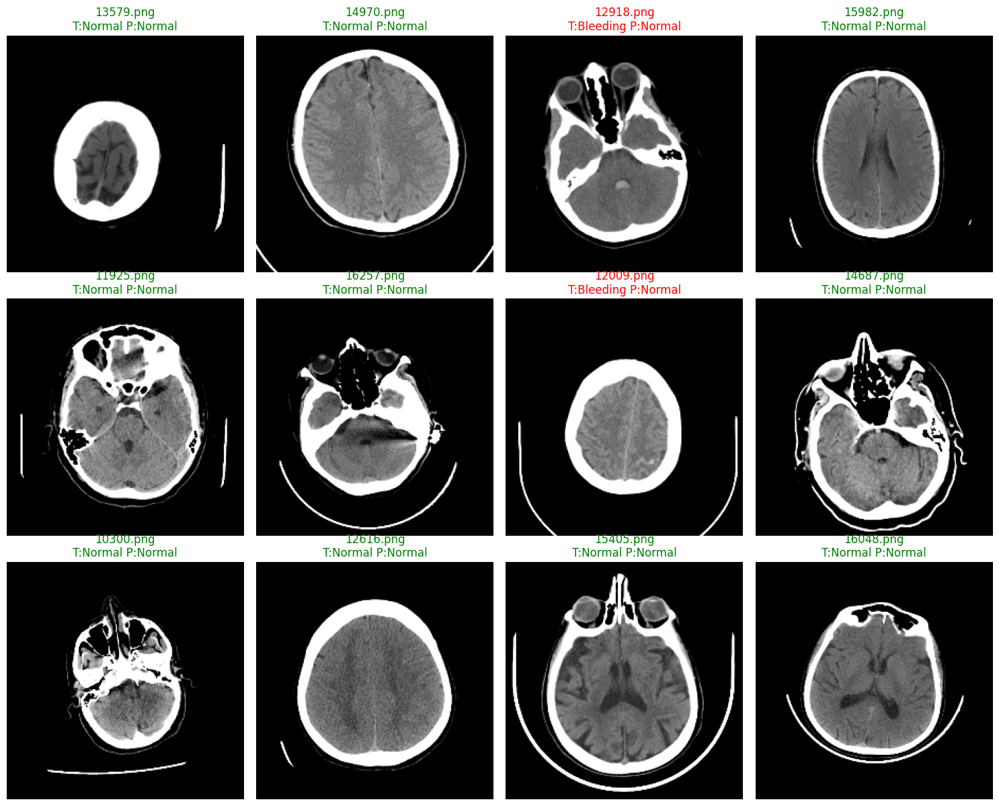

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


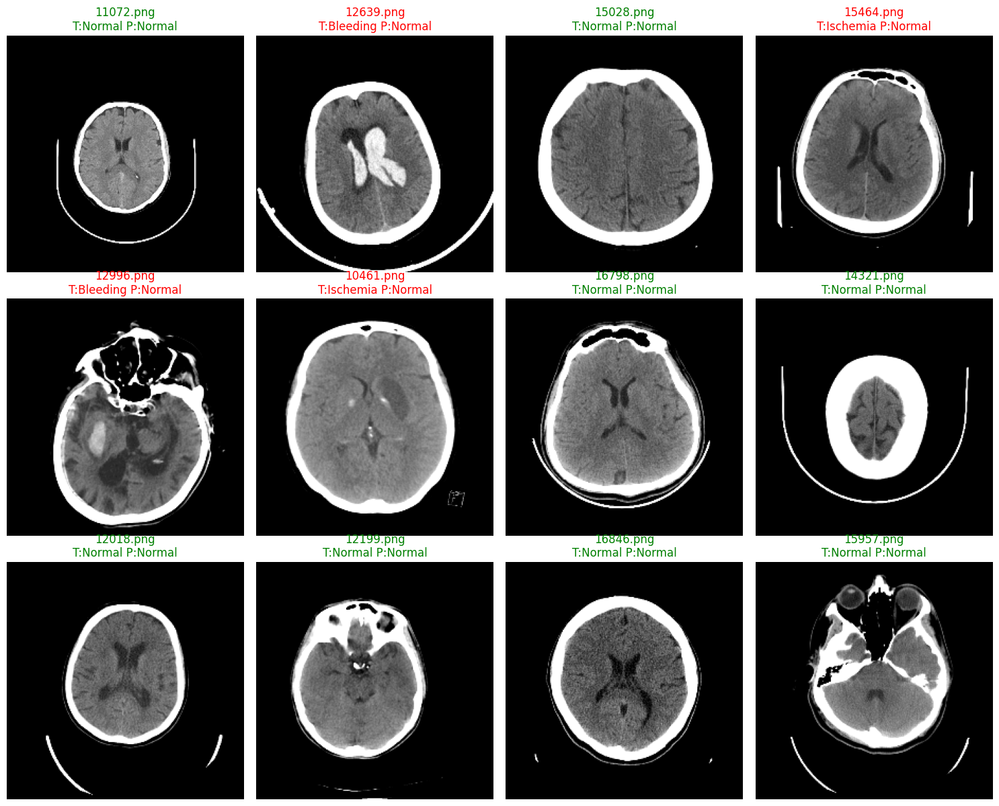

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

УСОВЕРШЕНСТВОВАННАЯ МОДЕЛЬ

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

2025-12-02 15:22:43.876947: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764688964.269383      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764688964.377493      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

data_path = "/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset"
test_path = os.path.join(data_path, "External_Test")
img_size = (224, 224)
batch_size = 16

AUTOTUNE = tf.data.AUTOTUNE
num_class = 3
classes = {"Bleeding": 1, "Ischemia": 2, "Normal": 0}
class_nae = ["Normal", "Bleeding", "Ischemia"]

In [ ]:
def safe_decode_png(path):
    img_bytes = tf.io.read_file(path)
    try:
        img = tf.image.decode_png(img_bytes, channels=1, dtype=tf.uint8)
    except Exception:
        img = tf.zeros([512, 512, 1], dtype=tf.uint8)
    # если пустой
    if tf.size(img) == 0:
        img = tf.zeros([512, 512, 1], dtype=tf.uint8)
    if tf.rank(img) == 2:
        img = tf.expand_dims(img, axis=-1)
    img.set_shape([None, None, 1])
    return img


In [ ]:
def collect_image_pairs(root_dir, class_map):
    pairs = []
    for cls_name, cls_id in class_map.items():
        img_dir = os.path.join(root_dir, cls_name, "PNG")
        if not os.path.exists(img_dir):
            img_dir = os.path.join(root_dir, cls_name, "images")
        if not os.path.exists(img_dir):
            print(f"Нет папки PNG для класса {cls_name}: {img_dir}")
            continue
        imgs = sorted(glob.glob(os.path.join(img_dir, "*.png")))
        for p in imgs:
            pairs.append((p, cls_id))
    return pairs

pairs = collect_image_pairs(data_path, classes)
print("Всего изображений (в основном наборе):", len(pairs))

Всего изображений (в основном наборе): 6650


In [ ]:
def balance_by_undersample(pairs, seed=SEED):
    by_class = {}
    for p, c in pairs:
        by_class.setdefault(c, []).append(p)
    sizes = {c: len(lst) for c, lst in by_class.items()}
    print("До балансировки:", sizes)
    min_sz = min(sizes.values())
    rng = random.Random(seed)
    balanced = []
    for c, paths in by_class.items():
        if len(paths) > min_sz:
            sampled = rng.sample(paths, min_sz)
        else:
            sampled = paths.copy()
        balanced += [(p, c) for p in sampled]
    rng.shuffle(balanced)
    sizes_after = {c: sum(1 for _p, cc in balanced if cc==c) for c in by_class}
    print("После undersampling:", sizes_after)
    return balanced

balanced_pairs = balance_by_undersample(pairs)

image_paths = [p for p,c in balanced_pairs]
labels_arr = np.array([c for p,c in balanced_pairs], dtype=np.int32)

До балансировки: {1: 1093, 2: 1130, 0: 4427}
После undersampling: {1: 1093, 2: 1093, 0: 1093}


In [ ]:
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels_arr, test_size=0.30, random_state=SEED, stratify=labels_arr)

print("Train / Val sizes:", len(train_paths), len(val_paths))

Train / Val sizes: 2295 984


In [ ]:
test_csv = os.path.join(test_path, "labels_new.csv")
df_raw = pd.read_csv(test_csv)
df_test = df_raw["labels"].str.split(";", expand=True)
df_test.columns = ["image_id", "Stroke"]
df_test = df_test[df_test["image_id"] != "image_id"]
df_test["image_id"] = df_test["image_id"].astype(str)
df_test["Stroke"] = df_test["Stroke"].astype(int)
test_png_dir = os.path.join(test_path, "PNG")
test_paths = []
test_labels = []
for _, row in df_test.iterrows():
    fname = f"{row['image_id']}.png"
    p = os.path.join(test_png_dir, fname)
    if os.path.exists(p):
        test_paths.append(p)
        test_labels.append(int(row["Stroke"]))
    else:
        print("Файл теста не найден:", p)
test_labels = np.array(test_labels, dtype=np.int32)
print("Test samples:", len(test_paths), "class counts:", {i:int(list(test_labels).count(i)) for i in sorted(set(test_labels))})

Test samples: 200 class counts: {0: 137, 1: 35, 2: 28}


In [ ]:
def parse_and_preprocess_train(path, label):
    img = safe_decode_png(path)
    img = tf.image.convert_image_dtype(img, tf.float32)
    if tf.random.uniform(()) < 0.5:
        img = tf.image.flip_left_right(img)
    if tf.random.uniform(()) < 0.15:
        img = tf.image.adjust_brightness(img, 0.03)
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = densenet_preprocess(img)
    return img, label

In [ ]:
def parse_and_preprocess_eval(path, label):
    img = safe_decode_png(path)
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = densenet_preprocess(img)
    return img, label

In [ ]:
def build_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
        ds = ds.map(parse_and_preprocess_train, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(parse_and_preprocess_eval, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = build_dataset(train_paths, train_labels, training=True)
val_ds = build_dataset(val_paths, val_labels, training=False)
test_ds = build_dataset(test_paths, test_labels, training=False)

I0000 00:00:1764689004.012578      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1764689004.013340      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [ ]:
for imgs, labs in train_ds.take(1):
    print("Train batch:", imgs.shape, labs.numpy()[:8])
for imgs, labs in val_ds.take(1):
    print("Val batch:", imgs.shape)
for imgs, labs in test_ds.take(1):
    print("Test batch:", imgs.shape)

Train batch: (16, 224, 224, 3) [2 0 1 0 2 2 2 1]
Val batch: (16, 224, 224, 3)
Test batch: (16, 224, 224, 3)


In [ ]:
cls_ids = np.unique(train_labels)
cw_arr = compute_class_weight(class_weight='balanced', classes=cls_ids, y=train_labels)
class_weights = np.ones(num_class, dtype=np.float32)
for i,c in enumerate(cls_ids):
    class_weights[c] = cw_arr[i]
print("class_weights:", class_weights)

class_weights: [1. 1. 1.]


Вариант 2 — почти то же, что вариант 1, но возвращает model, base и затем вручную размораживаетсят только последние N слоев. Это — стандартный «частичный fine-tune».

Частичный fine-tune часто дает лучший компромисс: модель адаптируется, а риск переобучения и «сломать» предобученные ранние фильтры ниже.

In [ ]:
def se_block(x, reduction=16):
    ch = int(x.shape[-1])
    se = layers.GlobalAveragePooling2D()(x)
    se = layers.Dense(max(ch//reduction, 4), activation='relu')(se)
    se = layers.Dense(ch, activation='sigmoid')(se)
    se = layers.Reshape((1,1,ch))(se)
    return layers.Multiply()([x, se])

def build_model(num_classes=num_class, input_shape=(img_size[0], img_size[1], 3)):
    base = DenseNet121(include_top=False, weights="imagenet", input_shape=input_shape)
    base.trainable = False
    x = base.output
    x = se_block(x, reduction=16)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.25)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inputs=base.input, outputs=out)
    return model, base

model, base = build_model()
model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,433,859 (28.36 MB)

 Trainable params: 395,843 (1.51 MB)

 Non-trainable params: 7,038,016 (26.85 MB)

In [ ]:
checkpoint_path = "best_densenet_finetune.h5"

ckpt = callbacks.ModelCheckpoint(checkpoint_path, monitor="val_sparse_categorical_accuracy",
                                 save_best_only=True, mode="max", verbose=1)
es = callbacks.EarlyStopping(monitor="val_sparse_categorical_accuracy", patience=6, restore_best_weights=True, verbose=1)
rlr = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='sparse_categorical_accuracy')])

print("Обучение головы")
history_head = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=[ckpt, es, rlr])

Обучение головы
Epoch 1/5


I0000 00:00:1764689042.017044     108 service.cc:148] XLA service 0x7bb040002570 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1764689042.018885     108 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1764689042.018914     108 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1764689045.271598     108 cuda_dnn.cc:529] Loaded cuDNN version 90300


  2/144 ━━━━━━━━━━━━━━━━━━━━ 9s 65ms/step - loss: 1.5072 - sparse_categorical_accuracy: 0.3906    

I0000 00:00:1764689057.972374     108 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - loss: 1.3813 - sparse_categorical_accuracy: 0.3843
Epoch 1: val_sparse_categorical_accuracy improved from -inf to 0.42073, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 83s 365ms/step - loss: 1.3807 - sparse_categorical_accuracy: 0.3845 - val_loss: 1.0514 - val_sparse_categorical_accuracy: 0.4207 - learning_rate: 0.0010
Epoch 2/5
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - loss: 1.1562 - sparse_categorical_accuracy: 0.4342
Epoch 2: val_sparse_categorical_accuracy improved from 0.42073 to 0.52439, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - loss: 1.1559 - sparse_categorical_accuracy: 0.4343 - val_loss: 0.9633 - val_sparse_categorical_accuracy: 0.5244 - learning_rate: 0.0010
Epoch 3/5
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 1.0448 - sparse_categorical_accuracy: 0.4816
Epoch 3: val_sparse_categorical_accuracy did not improve from 0.52439
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - loss: 1.0448 - sparse_categorical_accuracy: 0.4817 - val_loss: 0.9803 - val_sparse_categorical_accuracy: 0.5061 - learning_rate: 0.0010
Epoch 4/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 1.0283 - sparse_categorical_accuracy: 0.5048
Epoch 4: val_sparse_categorical_accuracy improved from 0.52439 to 0.52642, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - loss: 1.0283 - sparse_categorical_accuracy: 0.5048 - val_loss: 0.9607 - val_sparse_categorical_accuracy: 0.5264 - learning_rate: 0.0010
Epoch 5/5
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - loss: 0.9955 - sparse_categorical_accuracy: 0.5121
Epoch 5: val_sparse_categorical_accuracy improved from 0.52642 to 0.58130, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 81ms/step - loss: 0.9955 - sparse_categorical_accuracy: 0.5121 - val_loss: 0.9471 - val_sparse_categorical_accuracy: 0.5813 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.


In [ ]:
unfreeze_n = 80
for layer in base.layers[-unfreeze_n:]:
    layer.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='sparse_categorical_accuracy')])

print(f"fine-tune last {unfreeze_n} layers")
history_ft = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=[ckpt, es, rlr])

fine-tune last 80 layers
Epoch 1/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - loss: 1.5765 - sparse_categorical_accuracy: 0.4595
Epoch 1: val_sparse_categorical_accuracy did not improve from 0.58130
144/144 ━━━━━━━━━━━━━━━━━━━━ 98s 355ms/step - loss: 1.5763 - sparse_categorical_accuracy: 0.4595 - val_loss: 0.9259 - val_sparse_categorical_accuracy: 0.5681 - learning_rate: 1.0000e-05
Epoch 2/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.4482 - sparse_categorical_accuracy: 0.5050
Epoch 2: val_sparse_categorical_accuracy improved from 0.58130 to 0.60061, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - loss: 1.4476 - sparse_categorical_accuracy: 0.5051 - val_loss: 0.9057 - val_sparse_categorical_accuracy: 0.6006 - learning_rate: 1.0000e-05
Epoch 3/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.2939 - sparse_categorical_accuracy: 0.5174
Epoch 3: val_sparse_categorical_accuracy improved from 0.60061 to 0.60467, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - loss: 1.2939 - sparse_categorical_accuracy: 0.5174 - val_loss: 0.8877 - val_sparse_categorical_accuracy: 0.6047 - learning_rate: 1.0000e-05
Epoch 4/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 1.2456 - sparse_categorical_accuracy: 0.5292
Epoch 4: val_sparse_categorical_accuracy improved from 0.60467 to 0.62602, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - loss: 1.2458 - sparse_categorical_accuracy: 0.5293 - val_loss: 0.8522 - val_sparse_categorical_accuracy: 0.6260 - learning_rate: 1.0000e-05
Epoch 5/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 1.2396 - sparse_categorical_accuracy: 0.5506
Epoch 5: val_sparse_categorical_accuracy improved from 0.62602 to 0.64837, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - loss: 1.2392 - sparse_categorical_accuracy: 0.5506 - val_loss: 0.8166 - val_sparse_categorical_accuracy: 0.6484 - learning_rate: 1.0000e-05
Epoch 6/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 1.1922 - sparse_categorical_accuracy: 0.5554
Epoch 6: val_sparse_categorical_accuracy improved from 0.64837 to 0.65447, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - loss: 1.1920 - sparse_categorical_accuracy: 0.5554 - val_loss: 0.7962 - val_sparse_categorical_accuracy: 0.6545 - learning_rate: 1.0000e-05
Epoch 7/15
144/144 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 1.1097 - sparse_categorical_accuracy: 0.5567
Epoch 7: val_sparse_categorical_accuracy improved from 0.65447 to 0.66362, saving model to best_densenet_finetune.h5


... (3 outputs left out)

144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 85ms/step - loss: 0.9377 - sparse_categorical_accuracy: 0.5944 - val_loss: 0.7072 - val_sparse_categorical_accuracy: 0.6982 - learning_rate: 1.0000e-05
Epoch 12/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.9726 - sparse_categorical_accuracy: 0.6096
Epoch 12: val_sparse_categorical_accuracy improved from 0.69817 to 0.70833, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - loss: 0.9722 - sparse_categorical_accuracy: 0.6097 - val_loss: 0.6947 - val_sparse_categorical_accuracy: 0.7083 - learning_rate: 1.0000e-05
Epoch 13/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - loss: 0.9157 - sparse_categorical_accuracy: 0.6262
Epoch 13: val_sparse_categorical_accuracy improved from 0.70833 to 0.71037, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 83ms/step - loss: 0.9157 - sparse_categorical_accuracy: 0.6260 - val_loss: 0.6887 - val_sparse_categorical_accuracy: 0.7104 - learning_rate: 1.0000e-05
Epoch 14/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.8555 - sparse_categorical_accuracy: 0.6404
Epoch 14: val_sparse_categorical_accuracy did not improve from 0.71037
144/144 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - loss: 0.8553 - sparse_categorical_accuracy: 0.6404 - val_loss: 0.6858 - val_sparse_categorical_accuracy: 0.7093 - learning_rate: 1.0000e-05
Epoch 15/15
143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - loss: 0.8176 - sparse_categorical_accuracy: 0.6525
Epoch 15: val_sparse_categorical_accuracy improved from 0.71037 to 0.73476, saving model to best_densenet_finetune.h5


144/144 ━━━━━━━━━━━━━━━━━━━━ 12s 84ms/step - loss: 0.8175 - sparse_categorical_accuracy: 0.6525 - val_loss: 0.6567 - val_sparse_categorical_accuracy: 0.7348 - learning_rate: 1.0000e-05
Restoring model weights from the end of the best epoch: 15.


In [ ]:
if os.path.exists(checkpoint_path):
    model.load_weights(checkpoint_path)

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - loss: 0.7975 - sparse_categorical_accuracy: 0.6448
Test loss: 0.8207464814186096
Test accuracy: 0.6299999952316284


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Accuracy: 0.63
Classification report:
               precision    recall  f1-score   support

      Normal     0.8364    0.6715    0.7449       137
    Bleeding     0.3889    0.4000    0.3944        35
    Ischemia     0.3704    0.7143    0.4878        28

    accuracy                         0.6300       200
   macro avg     0.5319    0.5953    0.5424       200
weighted avg     0.6928    0.6300    0.6476       200



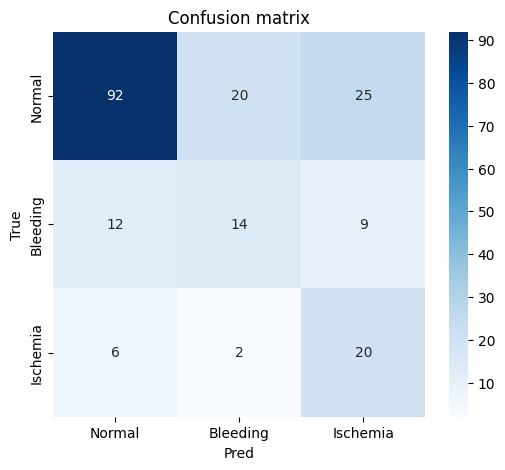

ROC AUC per class: [0.7902908121886224, 0.7719480519480519, 0.8444767441860466]


In [ ]:
def evaluate_and_report(model, ds, paths_list=None, labels_array=None):
    y_true = []
    y_pred = []
    probs = []
    for imgs, labs in ds:
        p = model.predict(imgs)
        probs.append(p)
        y_pred.extend(np.argmax(p, axis=1).tolist())
        y_true.extend(labs.numpy().tolist())
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    print("Accuracy:", np.mean(y_true == y_pred))
    print("Classification report:\n", classification_report(y_true, y_pred, target_names=class_nae, digits=4))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6,5)); sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_nae, yticklabels=class_nae, cmap="Blues")
    plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()
    try:
        probs = np.vstack(probs)
        y_bin = (np.arange(num_class) == y_true.reshape(-1,1)).astype(int)
        aucs = [roc_auc_score(y_bin[:, i], probs[:, i]) for i in range(num_class)]
        print("ROC AUC per class:", aucs)
    except Exception as e:
        print("ROC error:", e)
    return y_true, y_pred

y_true_test, y_pred_test = evaluate_and_report(model, test_ds)

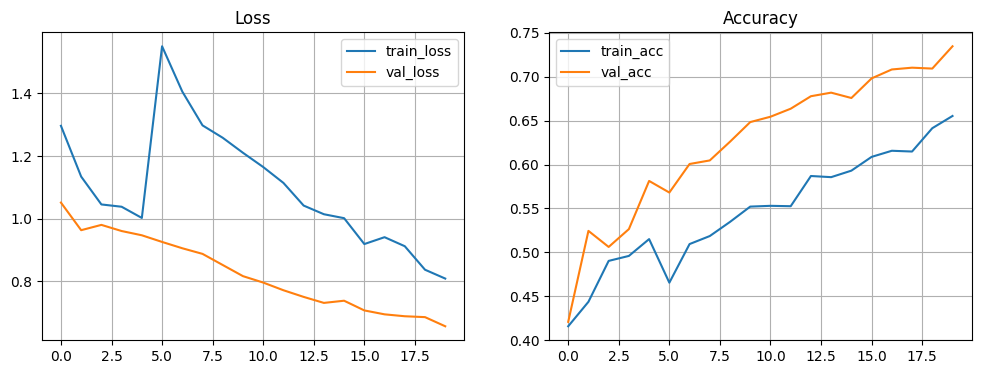

In [ ]:
def plot_history(h1, h2=None):
    hist = {}
    for key, val in h1.history.items():
        hist[key] = val[:]
    if h2 is not None:
        for key, val in h2.history.items():
            hist.setdefault(key, []).extend(val)
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(hist['loss'], label='train_loss')
    plt.plot(hist.get('val_loss', []), label='val_loss')
    plt.legend(); plt.grid(True); plt.title("Loss")
    plt.subplot(1,2,2)
    plt.plot(hist.get('sparse_categorical_accuracy') or hist.get('accuracy'), label='train_acc')
    plt.plot(hist.get('val_sparse_categorical_accuracy') or hist.get('val_accuracy'), label='val_acc')
    plt.legend(); plt.grid(True); plt.title("Accuracy")
    plt.show()

plot_history(history_head, history_ft)

In [ ]:
import os
import numpy as np

def show_test_predictions(model, paths, labels, n=12):
    plt.figure(figsize=(15, 12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 4
    rows = int(np.ceil(len(idxs)/cols))
    for i, idx in enumerate(idxs):
        img_raw = tf.io.read_file(paths[idx])
        img = tf.image.decode_png(img_raw, channels=1)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img_r = tf.image.resize(img, img_size)
        img3 = tf.image.grayscale_to_rgb(img_r)
        inp = densenet_preprocess(img3)
        pred = model.predict(tf.expand_dims(inp, axis=0))
        pcls = np.argmax(pred, axis=1)[0]
        tcls = labels[idx]
        plt.subplot(rows, cols, i+1)
        plt.imshow(img_r[:, :, 0], cmap='gray')
        color = "green" if int(pcls) == int(tcls) else "red"
        fname = os.path.basename(paths[idx])
        plt.title(f"{fname}\nT:{class_nae[int(tcls)]}  P:{class_nae[int(pcls)]}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


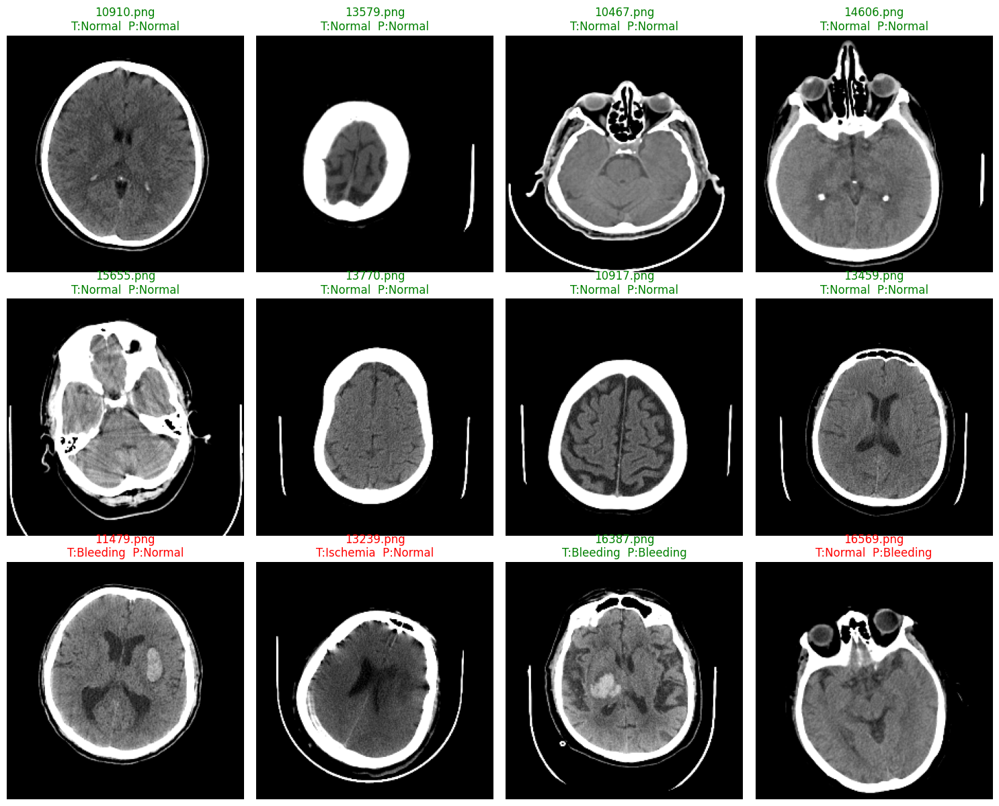

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


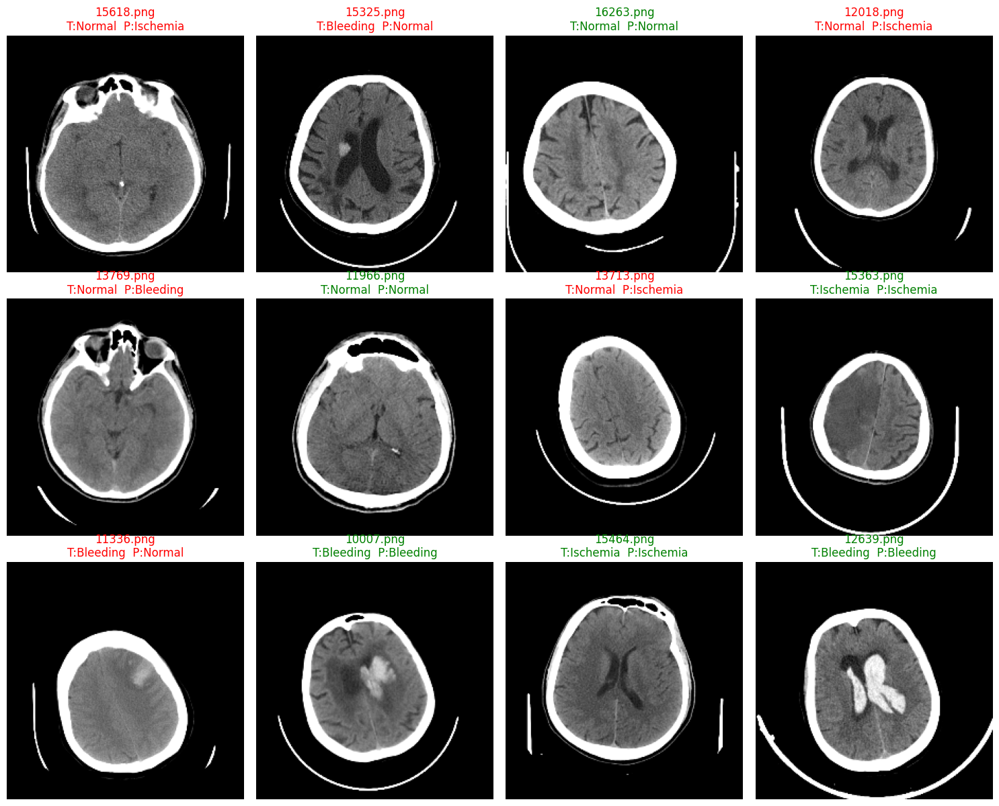

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


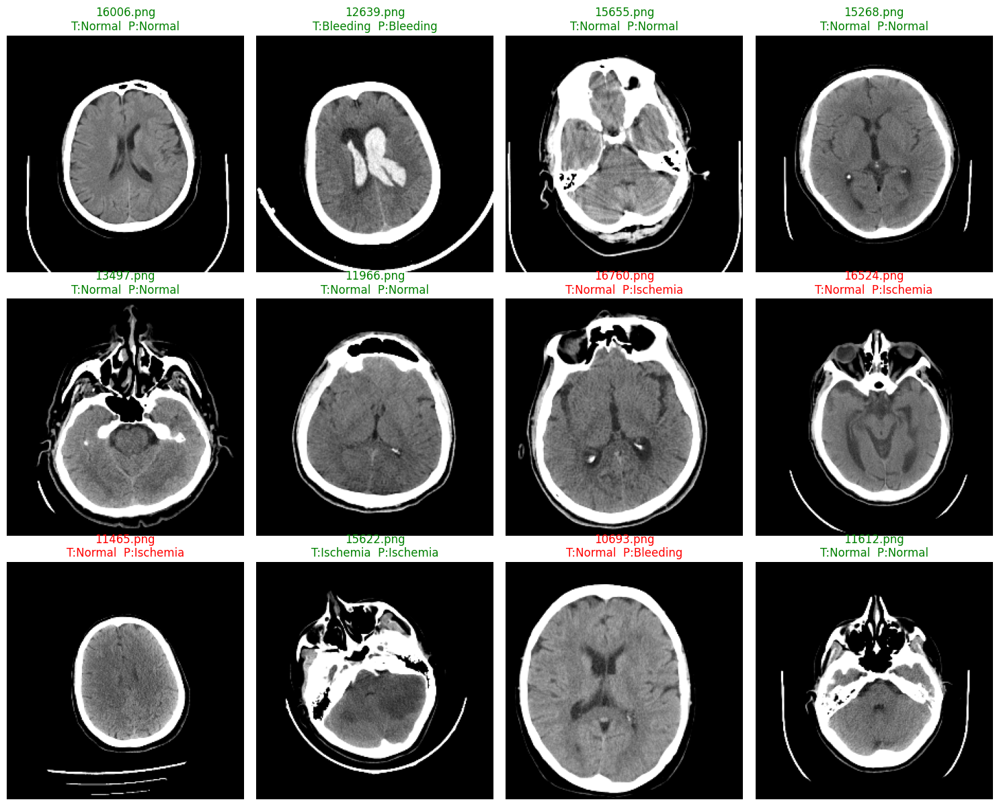

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


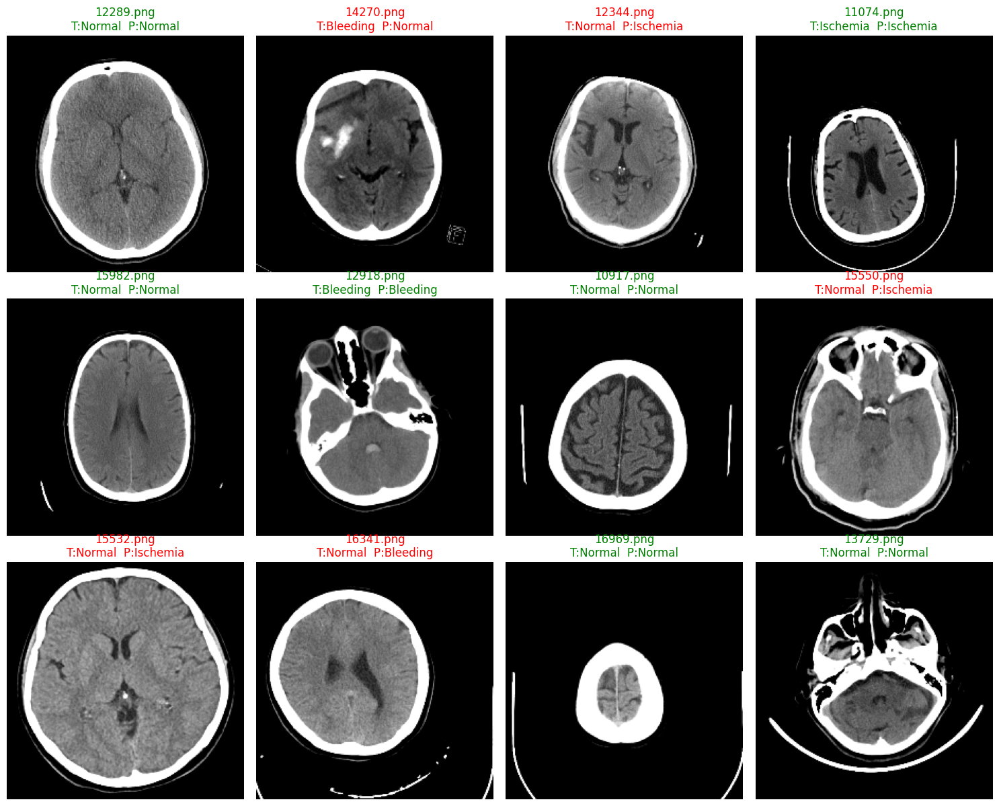

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

ПОЛНАЯ РАЗМОРОЗКА МОДЕЛИ

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

2025-12-09 03:22:07.792966: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765250528.001514      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765250528.054009      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [ ]:
import cv2

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)


data_path = "/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset"
test_path = os.path.join(data_path, "External_Test")

img_size = (320, 320)
batch_size = 16
AUTOTUNE = tf.data.AUTOTUNE

num_class = 3
classes = {"Bleeding": 1, "Ischemia": 2, "Normal": 0}
class_name = ["Normal", "Bleeding", "Ischemia"]


In [ ]:
def safe_decode_png(path):
    img_bytes = tf.io.read_file(path)
    try:
        img = tf.image.decode_png(img_bytes, channels=1, dtype=tf.uint8)
    except:
        img = tf.zeros([512, 512, 1], dtype=tf.uint8)

    if tf.rank(img) == 2:
        img = tf.expand_dims(img, axis=-1)

    img.set_shape([None, None, 1])
    return img


In [ ]:
def collect_image_pairs(root_dir, class_map):
    pairs = []
    for cls_name, cls_id in class_map.items():
        img_dir = os.path.join(root_dir, cls_name, "PNG")
        if not os.path.exists(img_dir):
            img_dir = os.path.join(root_dir, cls_name, "images")
        imgs = sorted(glob.glob(os.path.join(img_dir, "*.png")))
        for p in imgs:
            pairs.append((p, cls_id))
    return pairs

pairs = collect_image_pairs(data_path, classes)
print("Всего изображений:", len(pairs))


Всего изображений: 6650


In [ ]:
def balance_by_undersample(pairs, seed=SEED):
    by_class = {}
    for p, c in pairs:
        by_class.setdefault(c, []).append(p)
    sizes = {c: len(lst) for c, lst in by_class.items()}
    print("До балансировки:", sizes)
    min_sz = min(sizes.values())
    rng = random.Random(seed)
    balanced = []
    for c, paths in by_class.items():
        if len(paths) > min_sz:
            sampled = rng.sample(paths, min_sz)
        else:
            sampled = paths.copy()
        balanced += [(p, c) for p in sampled]
    rng.shuffle(balanced)
    sizes_after = {c: sum(1 for _p, cc in balanced if cc==c) for c in by_class}
    print("После undersampling:", sizes_after)
    return balanced

balanced_pairs = balance_by_undersample(pairs)

image_paths = [p for p,c in balanced_pairs]
labels_arr = np.array([c for p,c in balanced_pairs], dtype=np.int32)

До балансировки: {1: 1093, 2: 1130, 0: 4427}
После undersampling: {1: 1093, 2: 1093, 0: 1093}


In [ ]:
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels_arr, test_size=0.30, random_state=SEED, stratify=labels_arr)

print("Train / Val sizes:", len(train_paths), len(val_paths))

Train / Val sizes: 2295 984


In [ ]:
test_csv = os.path.join(test_path, "labels_new.csv")
df_raw = pd.read_csv(test_csv)
df_test = df_raw["labels"].str.split(";", expand=True)
df_test.columns = ["image_id", "Stroke"]
df_test = df_test[df_test["image_id"] != "image_id"]
df_test["image_id"] = df_test["image_id"].astype(str)
df_test["Stroke"] = df_test["Stroke"].astype(int)
test_png_dir = os.path.join(test_path, "PNG")
test_paths = []
test_labels = []
for _, row in df_test.iterrows():
    fname = f"{row['image_id']}.png"
    p = os.path.join(test_png_dir, fname)
    if os.path.exists(p):
        test_paths.append(p)
        test_labels.append(int(row["Stroke"]))
    else:
        print("Файл теста не найден:", p)
test_labels = np.array(test_labels, dtype=np.int32)
print("Test samples:", len(test_paths), "class counts:", {i:int(list(test_labels).count(i)) for i in sorted(set(test_labels))})

Test samples: 200 class counts: {0: 137, 1: 35, 2: 28}


In [ ]:
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

def parse_and_preprocess_train(path, label):
    img_raw = tf.io.read_file(path)

    # универсальный декодер (JPG/PNG)
    img = tf.image.decode_image(img_raw, channels=1, expand_animations=False)
    img = tf.image.convert_image_dtype(img, tf.float32)

    img.set_shape([None, None, 1])

    img = tf.image.resize(img, img_size)

    # лёгкая аугментация
    if tf.random.uniform(()) < 0.5:
        img = tf.image.flip_left_right(img)

    img = tf.image.grayscale_to_rgb(img)
    img = densenet_preprocess(img)

    return img, label


In [ ]:
import cv2
import numpy as np

def clahe_np(img):
    img = img.numpy() if hasattr(img, "numpy") else img
    img = (img * 255).astype(np.uint8)

    h, w, _ = img.shape
    img2 = img.reshape(h, w)

    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(img2)

    return cl.reshape(h, w, 1)


def apply_clahe(img):
    cl = tf.numpy_function(clahe_np, [img], tf.uint8)
    cl = tf.reshape(cl, [tf.shape(img)[0], tf.shape(img)[1], 1])
    return tf.cast(cl, tf.float32) / 255.0


In [ ]:
def parse_and_preprocess_eval(path, label):
    img_raw = tf.io.read_file(path)
    img = tf.image.decode_png(img_raw, channels=1)
    img = tf.cast(img, tf.float32) / 255.0

    img = apply_clahe(img)

    img = tf.image.resize(img, img_size)
    img = tf.image.grayscale_to_rgb(img)
    img = densenet_preprocess(img)

    return img, label

In [ ]:
import tensorflow as tf

bad = []

for p in train_paths:
    try:
        raw = tf.io.read_file(p)
        img = tf.image.decode_png(raw, channels=1)
        shape = img.shape
        if shape.rank is None:
            bad.append(p)
    except:
        bad.append(p)

bad[:20], len(bad)


I0000 00:00:1765250585.167103      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1765250585.167719      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


([], 0)

In [ ]:
def build_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)
        ds = ds.map(parse_and_preprocess_train, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(parse_and_preprocess_eval, num_parallel_calls=AUTOTUNE)

    return ds.batch(batch_size).prefetch(AUTOTUNE)

train_ds = build_dataset(train_paths, train_labels, training=True)
val_ds = build_dataset(val_paths, val_labels, training=False)
test_ds = build_dataset(test_paths, test_labels, training=False)


Вариант 3 — берется DenseNet, ставится base.trainable = True (полностью разморожено), и затем строится модель, где база вызывается как x = base(inputs, training=True) — это важно, потому что принудительно запускает поведение тренировочного режима внутри base (особенно влияет на BatchNorm). Затем добавляется минимальная голова (GAP + Dense). Это — полная разморозка, но с явным обучением всех слоев и явным включением режима training внутри base при прямом вызове.


Полностью разморожена вся база — все веса будут оптимизироваться. Это дает максимум гибкости, но и требует:
Больше данных либо сильной регуляризации, чтобы избежать переобучения.
Небольшого learning rate (обычно 1e-5..1e-6).
Больше времени и памяти.

base(inputs, training=True) — это заставляет BN работать как тренировочный внутри модели конфигурации. В tf.keras есть тонкости: если модель собрана и обучается через model.fit, Keras сам передает training флаг внутренним слоям. Но явный training=True гарантирует, что BN использует batch statistics и обновляет свои moving average при прямом вызове — это иногда полезно при тонкой настройке. Но надо быть осторожно: если создавать модель таким образом, где base всегда вызывается с training=True внутри ее слоя, то при inference BN будет все равно использовать batch statistics (плохая практика). Обычно лучше не жать training=True в момент сборки модели — позволить Keras контролировать это автоматически.

In [ ]:
base = DenseNet121(include_top=False, input_shape=(320,320,3), weights="imagenet")
base.trainable = True # полная разморозка

inputs = tf.keras.Input((320,320,3))
x = base(inputs, training=True)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(3, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 320, 320, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 10, 10, 1024)   │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 6,956,931 (26.54 MB)

 Non-trainable params: 83,648 (326.75 KB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-6),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"])

In [ ]:
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor="val_accuracy"),
    ReduceLROnPlateau(patience=2, factor=0.5, monitor="val_loss"),
    ModelCheckpoint("best_model.h5", save_best_only=True, monitor="val_accuracy")]


In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=100, callbacks=callbacks)


Epoch 1/100


I0000 00:00:1765250704.867587     108 service.cc:148] XLA service 0x7b5a6c005310 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1765250704.871048     108 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1765250704.871075     108 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1765250713.237815     108 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1765250798.907924     108 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


143/144 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.3483 - loss: 1.4588

In [ ]:
def tta_predict(model, image):
    preds = []

    preds.append(model.predict(image, verbose=0)[0])
    preds.append(model.predict(tf.image.flip_left_right(image), verbose=0)[0])
    preds.append(model.predict(tf.image.adjust_brightness(image, 0.03), verbose=0)[0])
    preds.append(model.predict(tf.image.adjust_contrast(image, 1.1), verbose=0)[0])

    return np.mean(preds, axis=0)


In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.5950 - loss: 0.8649
Test loss: 0.8063253164291382
Test accuracy: 0.6399999856948853


In [ ]:
preds = []
true = []

for batch_imgs, batch_labels in test_ds:
    for i in range(batch_imgs.shape[0]):
        img = tf.expand_dims(batch_imgs[i], 0)
        p = tta_predict(model, img)
        preds.append(np.argmax(p))
        true.append(int(batch_labels[i]))

preds = np.array(preds)
true = np.array(true)

print("Accuracy:", (preds == true).mean())
print(classification_report(true, preds, target_names=class_name))
print("Confusion matrix:\n", confusion_matrix(true, preds))


Accuracy: 0.685
              precision    recall  f1-score   support

      Normal       0.93      0.68      0.78       137
    Bleeding       0.55      0.83      0.66        35
    Ischemia       0.32      0.54      0.40        28

    accuracy                           0.69       200
   macro avg       0.60      0.68      0.61       200
weighted avg       0.78      0.69      0.71       200

Confusion matrix:
 [[93 16 28]
 [ 2 29  4]
 [ 5  8 15]]


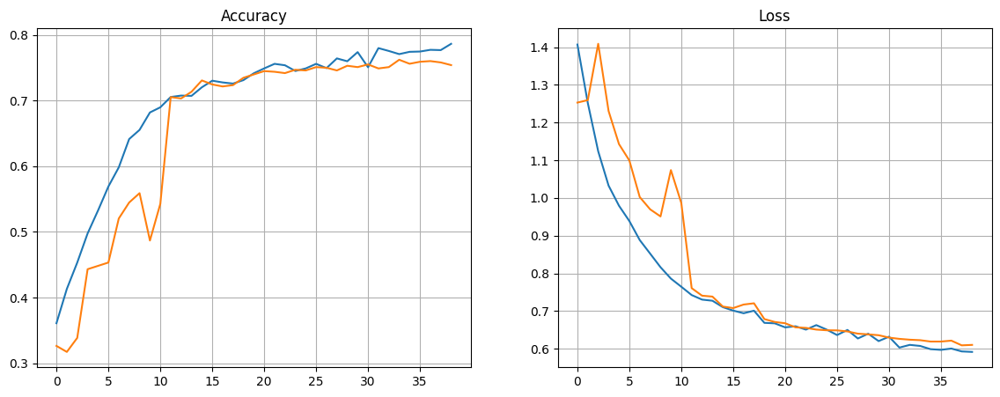

In [ ]:
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Accuracy")
plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Loss")
plt.grid()
plt.show()


In [ ]:
def show_test_predictions(model, paths, labels, n=12):
    plt.figure(figsize=(15,12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 4
    rows = int(np.ceil(len(idxs)/cols))

    for i, idx in enumerate(idxs):
        img_raw = tf.io.read_file(paths[idx])
        img = tf.image.decode_png(img_raw, channels=1)
        img = apply_clahe(img)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img_r = tf.image.resize(img, img_size)
        img3 = tf.image.grayscale_to_rgb(img_r)
        inp = densenet_preprocess(img3)
        inp = tf.expand_dims(inp, axis=0)

        pred = tta_predict(model, inp)
        pcls = np.argmax(pred)
        tcls = labels[idx]

        plt.subplot(rows, cols, i+1)
        plt.imshow(img_r[:,:,0], cmap="gray")
        color = "green" if pcls==tcls else "red"
        fname = os.path.basename(paths[idx])
        plt.title(f"{fname}\nT:{class_name[tcls]}  P:{class_name[pcls]}", color=color)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


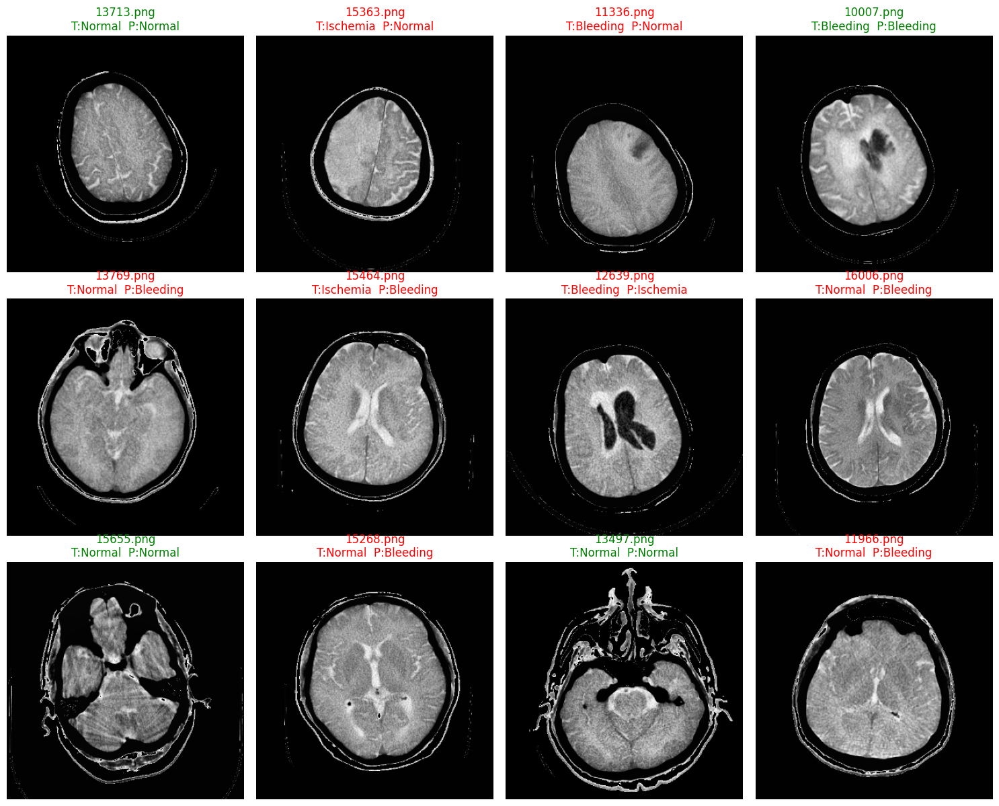

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

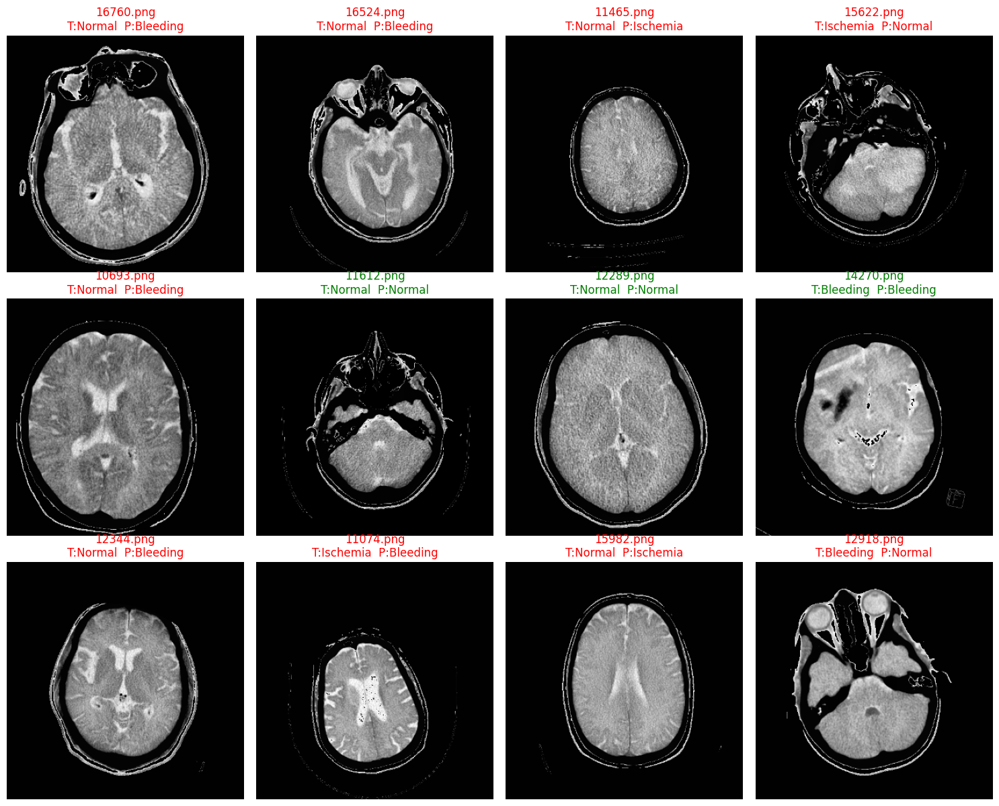

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

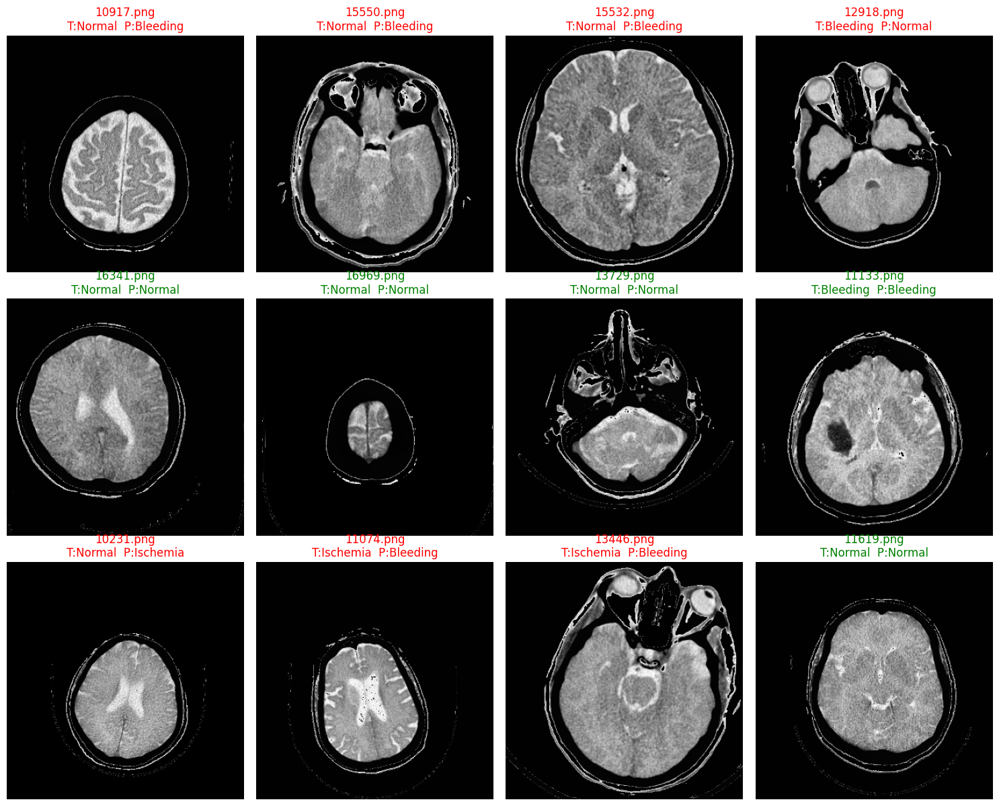

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

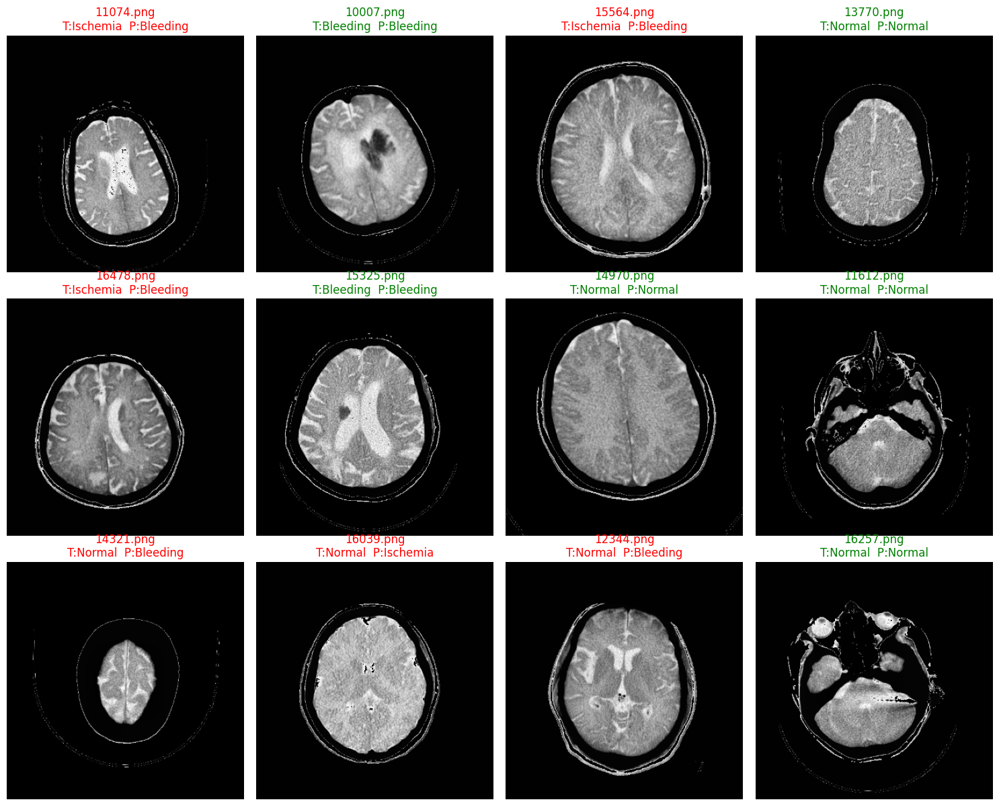

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)